# 01 - Exploratory Data Analysis
Run `python data/download_data.py` first. Works from the repo root or from `notebooks/` (also in Colab after cloning the repo).

In [2]:
!git clone https://github.com/wafaaalkaddaf-afk/greentrade-ai.git
%cd greentrade-ai
!pip install -q pyyaml
!python data/download_data.py

Cloning into 'greentrade-ai'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 72 (delta 23), reused 47 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 32.72 KiB | 5.45 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/greentrade-ai
Extracted: ['Steel_industry_data.csv']
Done -> /content/greentrade-ai/data/raw/Steel_industry_data.csv


In [3]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import load_config, load_raw
cfg = load_config()
raw = pd.read_csv(cfg["data"]["raw_path"])
df = load_raw(cfg["data"]["raw_path"])
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
3,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
4,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load


## 1. Size, types, missing values, duplicates

In [4]:
print("Raw shape:", raw.shape, "| after cleaning:", df.shape)
print("Date range:", df['date'].min(), "->", df['date'].max())
print("Missing values per column:"); print(raw.isna().sum())
print("Duplicated rows (raw):", int(raw.duplicated().sum()))
print("Duplicated timestamps (raw):", int(raw['date'].duplicated().sum()))
print("Time step between readings:"); print(df['date'].diff().dropna().value_counts())
raw.dtypes

Raw shape: (35040, 11) | after cleaning: (35040, 11)
Date range: 2018-01-01 00:00:00 -> 2018-12-31 23:45:00
Missing values per column:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64
Duplicated rows (raw): 0
Duplicated timestamps (raw): 0
Time step between readings:
date
0 days 00:15:00    35039
Name: count, dtype: int64


,0
date,object
Usage_kWh,float64
Lagging_Current_Reactive.Power_kVarh,float64
Leading_Current_Reactive_Power_kVarh,float64
CO2(tCO2),float64
Lagging_Current_Power_Factor,float64
Leading_Current_Power_Factor,float64
NSM,int64
WeekStatus,object
Day_of_week,object


**Conclusion:** The dataset has 35040 rows and 11 columns, covering 2018-01-01 00:00 to 2018-12-31 23:45 at 15-minute steps. Missing values: 0. Duplicated rows/timestamps: 0. Therefore the cleaning decision is: no cleaning needed, keep all rows (no imputation, no dropping).

## 2. Target distribution and outliers

count    35040.000000
mean        27.386892
std         33.444380
min          0.000000
25%          3.200000
50%          4.570000
75%         51.237500
max        157.180000
Name: Usage_kWh, dtype: float64
IQR outliers: 328 (0.94%) | zero readings: 1


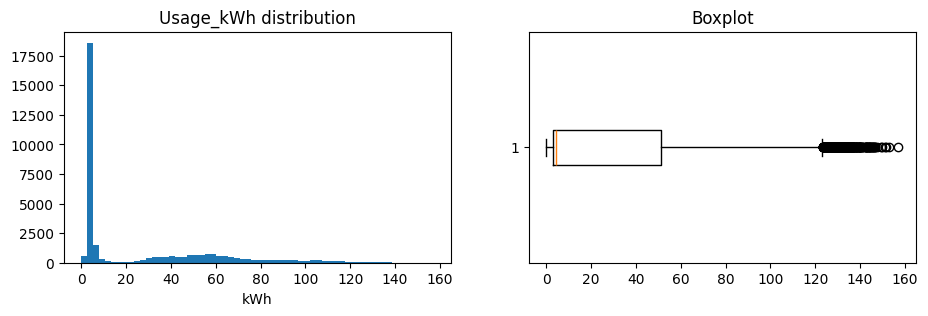

In [5]:
s = df['Usage_kWh']
print(s.describe())
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
out = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
print(f"IQR outliers: {out} ({out/len(s):.2%}) | zero readings: {(s==0).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(s, bins=60); ax[0].set_title('Usage_kWh distribution'); ax[0].set_xlabel('kWh')
ax[1].boxplot(s, vert=False); ax[1].set_title('Boxplot')
plt.show()

**Conclusion:** Usage_kWh ranges from 0.0 to 157.18 kWh (mean 27.39, median 4.57). The distribution is right-skewed with two peaks: a huge one near 0-5 kWh (idle periods) and a broad one around 40-70 kWh (production). Outliers by IQR: 0.94% (328 readings). Decision: keep them, they are real production peaks; MAE is less sensitive to them than RMSE.

## 3. Feature ranges and categorical columns

In [6]:
print(df.describe().T[['min','mean','max','std']].round(2))
for c in ['WeekStatus', 'Day_of_week', 'Load_Type']:
    if c in df:
        print(f"\n{c}:"); print(df[c].value_counts())

                                                      min  \
date                                  2018-01-01 00:00:00   
Usage_kWh                                             0.0   
Lagging_Current_Reactive.Power_kVarh                  0.0   
Leading_Current_Reactive_Power_kVarh                  0.0   
CO2(tCO2)                                             0.0   
Lagging_Current_Power_Factor                          0.0   
Leading_Current_Power_Factor                          0.0   
NSM                                                   0.0   

                                                     mean  \
date                                  2018-07-02 11:52:30   
Usage_kWh                                       27.386892   
Lagging_Current_Reactive.Power_kVarh            13.035384   
Leading_Current_Reactive_Power_kVarh             3.870949   
CO2(tCO2)                                        0.011524   
Lagging_Current_Power_Factor                    80.578056   
Leading_Current_Power_F

**Conclusion:** The numeric features have very different ranges (0 to 85500), so they must be scaled (standard scaler, fitted on train only). Text columns: WeekStatus, Day_of_week, Load_Type, so the dataset has mixed feature types; we encode the time information as numeric time features instead.

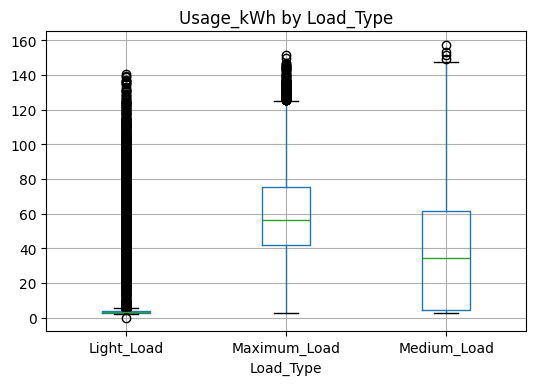

In [7]:
if 'Load_Type' in df:
    df.boxplot(column='Usage_kWh', by='Load_Type', figsize=(6,4)); plt.suptitle(''); plt.title('Usage_kWh by Load_Type'); plt.show()

**Conclusion:** The numeric features have very different ranges (0 to 85500), so they must be scaled (standard scaler, fitted on train only). Text columns: WeekStatus, Day_of_week, Load_Type, so the dataset has mixed feature types; we encode the time information as numeric time features instead.

## 4. Correlations

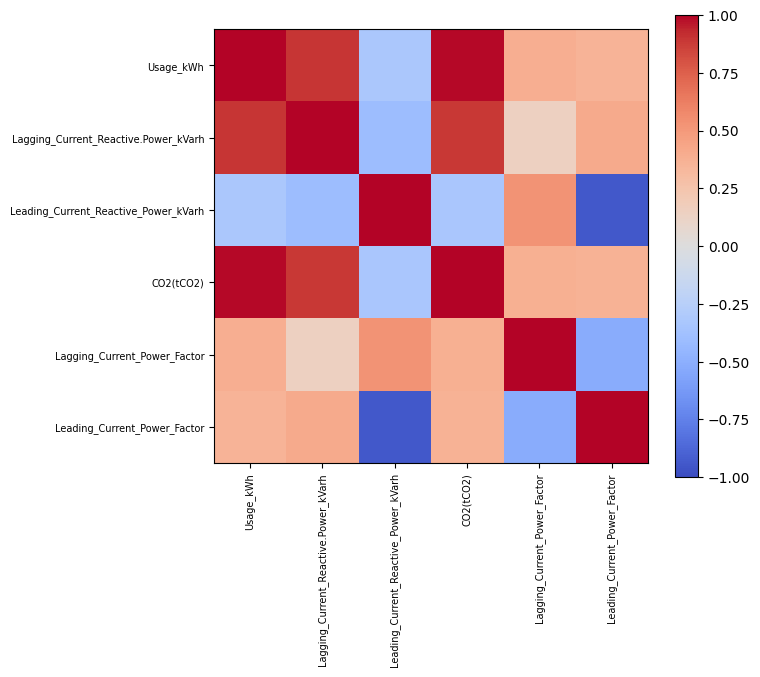

Usage_kWh                               1.000
CO2(tCO2)                               0.988
Lagging_Current_Reactive.Power_kVarh    0.896
Lagging_Current_Power_Factor            0.386
Leading_Current_Power_Factor            0.354
Leading_Current_Reactive_Power_kVarh   -0.325
Name: Usage_kWh, dtype: float64


In [8]:
num = df.select_dtypes('number').drop(columns=['NSM'], errors='ignore')
corr = num.corr()
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im); plt.show()
print(corr['Usage_kWh'].sort_values(ascending=False).round(3))

**Conclusion:** Usage_kWh is most correlated with CO2(tCO2) (r = 0.988) and Lagging_Current_Reactive_Power_kVarh (r = 0.896). CO2 follows consumption closely, which is why carbon analysis can be built on the forecast. Weak features: Leading_Current_Power_Factor (0.354) and Leading_Current_Reactive_Power_kVarh (-0.325).

## 5. Time patterns

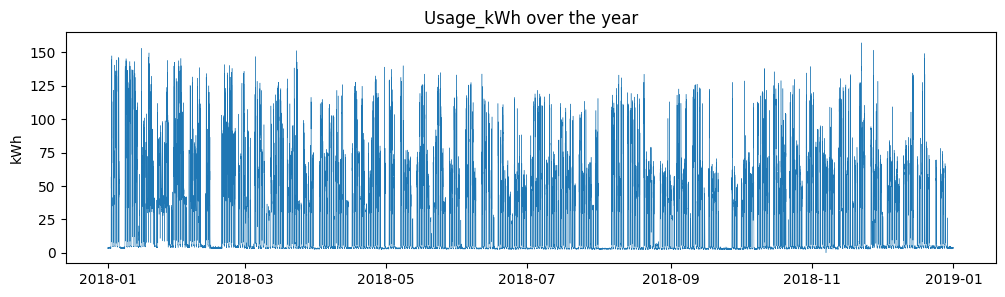

In [9]:
fig, ax = plt.subplots(figsize=(12,3))
ax.plot(df['date'], df['Usage_kWh'], lw=0.3); ax.set_title('Usage_kWh over the year'); ax.set_ylabel('kWh')
plt.show()

In [14]:
daily_max = df.set_index('date')['Usage_kWh'].resample('D').max()
idle = daily_max[(daily_max < 10) & (daily_max.index.dayofweek < 5)]
print(len(idle)); print(idle.index.date)

12
[datetime.date(2018, 1, 1) datetime.date(2018, 2, 15)
 datetime.date(2018, 2, 16) datetime.date(2018, 5, 1)
 datetime.date(2018, 8, 1) datetime.date(2018, 8, 2)
 datetime.date(2018, 8, 3) datetime.date(2018, 9, 24)
 datetime.date(2018, 9, 25) datetime.date(2018, 9, 26)
 datetime.date(2018, 12, 25) datetime.date(2018, 12, 31)]


**Conclusion:** Over the year consumption is stable (no strong seasonal trend; the same on/off pattern repeats all year). Visible gaps or unusual periods: 12 weekdays with no production (daily maximum below 10 kWh): 1 Jan, 15-16 Feb, 1 May, 1-3 Aug, 24-26 Sep, 25 Dec and 31 Dec. Some coincide with public holidays (1 Jan, 1 May, 25 Dec), but the dataset does not state the cause of the others.


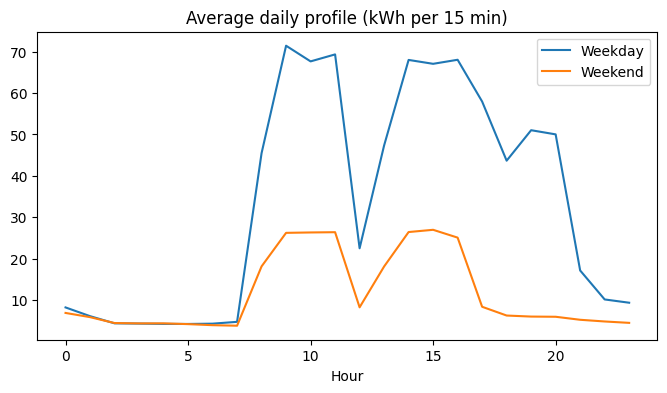

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Weekday,8.2,6.1,4.4,4.3,4.3,4.3,4.3,4.8,45.5,71.4,...,68.0,67.1,68.0,58.0,43.7,51.0,50.0,17.2,10.2,9.4
Weekend,6.9,5.9,4.5,4.4,4.4,4.2,4.0,3.8,18.2,26.3,...,26.4,27.0,25.1,8.4,6.3,6.0,6.0,5.3,4.9,4.5


In [10]:
d = df.assign(hour=df['date'].dt.hour, weekend=df['date'].dt.dayofweek>=5)
prof = d.groupby(['weekend','hour'])['Usage_kWh'].mean().unstack(0)
prof.columns = ['Weekday','Weekend']
prof.plot(figsize=(8,4), title='Average daily profile (kWh per 15 min)'); plt.xlabel('Hour'); plt.show()
prof.round(1).T

**Conclusion:** On weekdays consumption rises at 8 h and falls at 21 h, with a peak around 71 kWh (per 15-min reading) and a dip near 12:00 (lunch). On weekends it is lower (peak only about 27 kWh). Decision: add hour, day-of-week and weekend features.

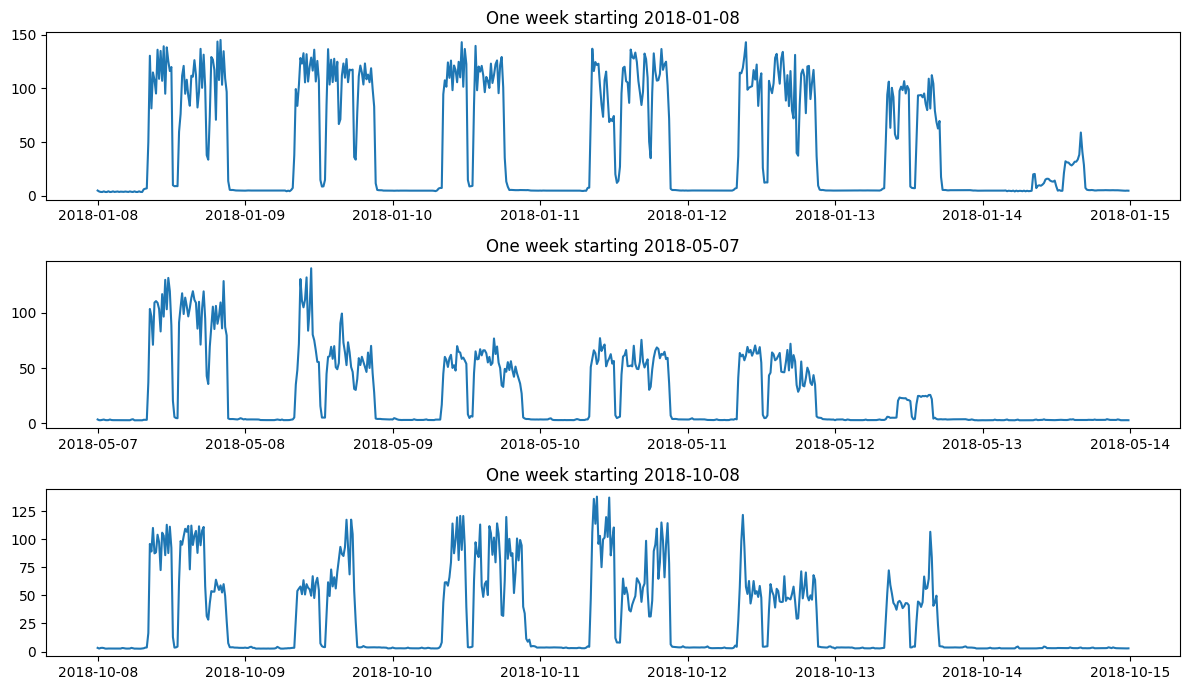

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, start in zip(axes, ['2018-01-08', '2018-05-07', '2018-10-08']):
    w = df[(df['date'] >= start) & (df['date'] < pd.Timestamp(start) + pd.Timedelta(days=7))]
    ax.plot(w['date'], w['Usage_kWh']); ax.set_title(f'One week starting {start}')
plt.tight_layout(); plt.show()

**Conclusion:** The weekly pattern is stable (repeats every week: high-activity weekdays with two daily peaks, then a much lower weekend). Differences between the three weeks: the peak level changes from week to week (January weekdays reach about 120-145 kWh, in May only the first two days are high and Wednesday to Friday reach about 60-75 kWh, and in October the weekdays vary between about 60 and 140 kWh with Thursday the highest), and weekend activity differs (small Saturday peak in all three weeks, near-idle Sunday). The day-to-day level is not constant, so "tomorrow = today" can be wrong when the next day has a different level.

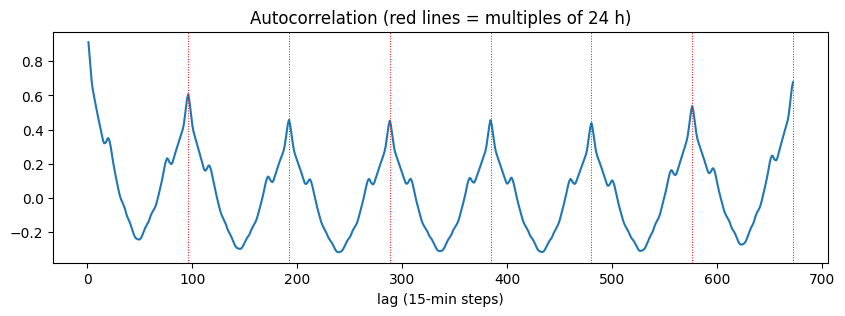

autocorr at lag 96 (24 h): 0.606 | lag 672 (7 days): 0.677


In [12]:
s = df['Usage_kWh']
ac = [s.autocorr(l) for l in range(1, 7*96+1)]
fig, ax = plt.subplots(figsize=(10,3)); ax.plot(range(1, len(ac)+1), ac)
for k in range(1,8): ax.axvline(96*k, color='r', ls=':', lw=0.7)
ax.set_title('Autocorrelation (red lines = multiples of 24 h)'); ax.set_xlabel('lag (15-min steps)'); plt.show()
print('autocorr at lag 96 (24 h):', round(s.autocorr(96),3), '| lag 672 (7 days):', round(s.autocorr(672),3))

**Conclusion:** Autocorrelation at lag 96 (24 h) = 0.606 and at lag 672 (7 days) = 0.677. Strong daily repetition, so a 24 h input window (96 steps) is justified and 'tomorrow = today' is the right trivial baseline. The weekly lag is slightly higher, so weekly repetition is also strong.

## 6. Do train / validation / test look alike?

In [13]:
n = len(df); i1, i2 = int(n*.70), int(n*.85)
for name, part in [('train', df.iloc[:i1]), ('val', df.iloc[i1:i2]), ('test', df.iloc[i2:])]:
    print(f"{name:5s} {part['date'].min().date()} -> {part['date'].max().date()}  mean={part['Usage_kWh'].mean():6.2f}  std={part['Usage_kWh'].std():6.2f}  weekend share={(part['date'].dt.dayofweek>=5).mean():.2f}")

train 2018-01-01 -> 2018-09-13  mean= 28.69  std= 34.39  weekend share=0.28
val   2018-09-13 -> 2018-11-07  mean= 24.08  std= 30.64  weekend share=0.29
test  2018-11-07 -> 2018-12-31  mean= 24.59  std= 31.17  weekend share=0.29


**Conclusion:** Train / validation / test have mean 28.69 / 24.08 / 24.59 and weekend share 0.28 / 0.29 / 0.29. The periods are similar (val and test are almost identical; train has a mean about 4.6 kWh higher), so a mild distribution shift is expected; this is discussed in the limitations.

In [15]:
from src.data import build_datasets
d = build_datasets(cfg)
print(len(d['feature_names']), d['feature_names'])
print('train X shape:', d['train'][0].shape)

11 ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend']
train X shape: (24337, 96, 11)


## Findings table (fill from the outputs above, then delete this line)

| # | Finding (with the number you saw) | Modelling decision it leads to |
|---|---|---|
| 1 | Missing values / duplicates: ... | e.g. no imputation needed / drop duplicates |
| 2 | Target is skewed / has outliers: ... | e.g. keep outliers (real peaks), use MAE |
| 3 | Daily cycle: autocorrelation at lag 96 = ... | 24 h input window (96 steps); seasonal-naive baseline |
| 4 | Weekday vs weekend profile differs: ... | add `is_weekend` and day-of-week features |
| 5 | Features most correlated with Usage_kWh: ... | keep them as inputs (only past values are used) |
| 6 | Train / val / test statistics differ: ... | report val and test separately; discuss distribution shift |